<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Ejercicios/Soluciones/05_Taller_Embeddings_RNN_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Taller práctico: embeddings, RNN, LSTM y GRU (solución)</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Instrucciones</h2>

Solución de referencia del taller [`05_Taller_Embeddings_RNN.ipynb`](../05_Taller_Embeddings_RNN.ipynb).

Hay muchas soluciones válidas: esta es una de ellas. Compara tus resultados y, sobre todo, tus conclusiones.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Ejercicio 1. Decisiones de vectorización</span>](#ejercicio-1)
- [<span style="color: #005C99;">Ejercicio 2. Clasificación frente a regresión ordinal</span>](#ejercicio-2)
- [<span style="color: #005C99;">Ejercicio 3. Arquitecturas recurrentes</span>](#ejercicio-3)
- [<span style="color: #005C99;">Ejercicio 4. Embeddings preentrenados y cantidad de datos</span>](#ejercicio-4)
- [<span style="color: #005C99;">Ejercicio 5. Análisis de errores en un problema ordinal</span>](#ejercicio-5)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn tensorflow gensim datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # oculta mensajes informativos de TensorFlow

import re
import string
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

from gensim.models import Word2Vec
from datasets import load_dataset
from sklearn.metrics import accuracy_score, mean_absolute_error, ConfusionMatrixDisplay

resenas = load_dataset("SetFit/amazon_reviews_multi_es")
df_train = resenas["train"].to_pandas().sample(n=50_000, random_state=SEED)
df_val = resenas["validation"].to_pandas()
df_test = resenas["test"].to_pandas()

X_train_txt, y_train = df_train.text.tolist(), df_train.label.to_numpy()   # etiquetas 0..4 = 1..5 estrellas
X_val_txt, y_val = df_val.text.tolist(), df_val.label.to_numpy()
X_test_txt, y_test = df_test.text.tolist(), df_test.label.to_numpy()
print(f"Entrenamiento: {len(X_train_txt)} | Validación: {len(X_val_txt)} | Prueba: {len(X_test_txt)}")
print("Distribución de estrellas en entrenamiento:", (pd.Series(y_train + 1).value_counts(normalize=True).sort_index().round(3)).to_dict())

Entrenamiento: 50000 | Validación: 5000 | Prueba: 5000
Distribución de estrellas en entrenamiento: {1: 0.199, 2: 0.199, 3: 0.199, 4: 0.2, 5: 0.203}


---

<a id="ejercicio-1"></a>
<h2 style="color: #007ACC;">Ejercicio 1. Decisiones de vectorización</h2>

**Objetivo:** elegir la longitud de las secuencias y el tamaño del vocabulario a partir de los datos, no a ojo.

1. Calcula la distribución del número de palabras por reseña en entrenamiento (usa la función `estandarizar` dada y `split()`). Reporta los percentiles 50, 90, 95 y 99 por número de estrellas. ¿Las reseñas negativas son más largas o más cortas?
2. Elige `LONGITUD` como el percentil 95 redondeado a la decena superior. ¿Qué fracción de reseñas se recorta?
3. Cuenta la frecuencia de cada palabra en entrenamiento y grafica la **cobertura**: qué fracción de los tokens del conjunto de validación queda dentro del vocabulario si se usan las $V$ palabras más frecuentes, para $V$ entre 1 000 y 50 000. Elige `MAX_TOKENS` como el menor $V$ que cubre al menos el 97 % de los tokens.
4. Crea la capa `TextVectorization` con esas decisiones y vectoriza los tres conjuntos (`X_train`, `X_val`, `X_test`).

In [3]:
def estandarizar(texto):
    """Minúsculas y eliminación de puntuación, incluidos los signos de apertura del español."""
    texto = tf.strings.lower(texto)
    return tf.strings.regex_replace(texto, r"[¡¿«»“”\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~!']", " ")


def palabras(texto):
    return estandarizar(texto).numpy().decode().split()


tokens_train = [palabras(t) for t in X_train_txt]
longitudes = pd.Series([len(t) for t in tokens_train])
pd.DataFrame({e + 1: longitudes[y_train == e].quantile([0.5, 0.9, 0.95, 0.99]).values for e in range(5)},
             index=["p50", "p90", "p95", "p99"]).T.rename_axis("estrellas")

,p50,p90,p95,p99
estrellas,,,,
1,23.0,55.0,71.0,114.48
2,24.0,60.0,78.0,125.65
3,23.0,56.0,74.0,122.39
4,21.0,51.0,67.0,113.00
5,20.0,49.0,65.0,116.00


LONGITUD = 80 | reseñas recortadas: 3.5%


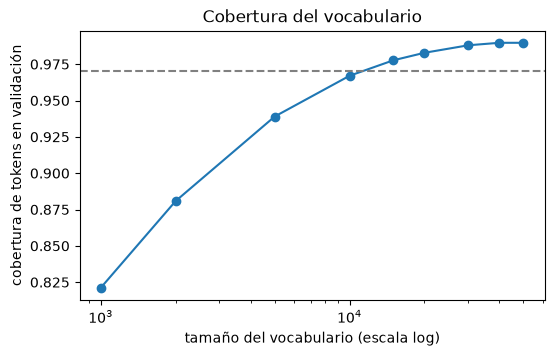

MAX_TOKENS = 15000 (cobertura 97.8%)


In [4]:
LONGITUD = int(np.ceil(longitudes.quantile(0.95) / 10) * 10)
print(f"LONGITUD = {LONGITUD} | reseñas recortadas: {(longitudes > LONGITUD).mean():.1%}")

frec = Counter(w for t in tokens_train for w in t)
ranking = {w: r for r, (w, _) in enumerate(frec.most_common())}
tokens_val = [w for t in X_val_txt for w in palabras(t)]
rangos_val = np.array([ranking.get(w, 10 ** 9) for w in tokens_val])

tamanos = np.array([1000, 2000, 5000, 10_000, 15_000, 20_000, 30_000, 40_000, 50_000])
cobertura = np.array([(rangos_val < V).mean() for V in tamanos])
MAX_TOKENS = int(tamanos[np.argmax(cobertura >= 0.97)])

plt.figure(figsize=(6, 3.5))
plt.semilogx(tamanos, cobertura, marker="o")
plt.axhline(0.97, ls="--", c="gray")
plt.xlabel("tamaño del vocabulario (escala log)")
plt.ylabel("cobertura de tokens en validación")
plt.title("Cobertura del vocabulario")
plt.show()
print(f"MAX_TOKENS = {MAX_TOKENS} (cobertura {cobertura[tamanos == MAX_TOKENS][0]:.1%})")

In [5]:
vectorizador = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=LONGITUD, standardize=estandarizar)
vectorizador.adapt(X_train_txt)
vocab = [str(w) for w in vectorizador.get_vocabulary()]
X_train, X_val, X_test = (vectorizador(np.array(t)).numpy() for t in (X_train_txt, X_val_txt, X_test_txt))
print(X_train.shape, X_val.shape, X_test.shape)

(50000, 80) (5000, 80) (5000, 80)


**Interpretación:** las reseñas son cortas y su longitud varía poco entre clases; las negativas tienden a ser algo más largas (quien está insatisfecho suele explicar el problema). Con el percentil 95 se recorta solo una pequeña fracción de reseñas, y cada palabra adicional de relleno solo cuesta cómputo. La curva de cobertura muestra rendimientos decrecientes: las primeras miles de palabras cubren la gran mayoría de los tokens (ley de Zipf, cuaderno 00), y pasar de 20 000 a 50 000 palabras apenas mejora la cobertura mientras multiplica el tamaño de la capa de embedding.

---

<a id="ejercicio-2"></a>
<h2 style="color: #007ACC;">Ejercicio 2. Clasificación frente a regresión ordinal</h2>

**Objetivo:** comparar dos formas de modelar una etiqueta ordenada y evaluarlas con métricas adecuadas.

Usa la arquitectura de promedio de embeddings del cuaderno 11 (`Embedding(MAX_TOKENS, 64, mask_zero=True)` → `GlobalAveragePooling1D` → `Dense(32, relu)`), con dos cabezas distintas:

- **Clasificación:** `Dense(5, softmax)` con `sparse_categorical_crossentropy`. Predicción: la clase más probable.
- **Regresión:** `Dense(1)` lineal con error cuadrático medio sobre la etiqueta 0–4. Predicción: el valor redondeado y recortado al rango [0, 4].

1. Entrena ambos modelos (máximo 10 épocas, parada temprana con `patience=2` sobre la pérdida de validación).
2. Implementa `metricas(y_real, y_pred)` que devuelva: **exactitud**, **exactitud ±1** (fracción de predicciones a una estrella o menos de la real) y **error absoluto medio** (MAE) en estrellas.
3. Evalúa ambos en **validación**. Agrega una tercera variante: la clasificación, pero prediciendo el **valor esperado** $\sum_k k\, P(k)$ redondeado en lugar de la clase más probable.
4. ¿Qué modelo elegirías si la métrica principal fuera la exactitud? ¿Y si fuera el MAE? Explica la diferencia.

In [6]:
def base_promedio():
    return [keras.Input(shape=(LONGITUD,), dtype="int64"),
            layers.Embedding(MAX_TOKENS, 64, mask_zero=True),
            layers.GlobalAveragePooling1D(),
            layers.Dense(32, activation="relu")]


def entrenar(modelo, X, y, epocas=10, lote=256, paciencia=2):
    return modelo.fit(X, y, validation_data=(X_val, y_val.astype(y.dtype)),
                      epochs=epocas, batch_size=lote, verbose=0,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia,
                                                               restore_best_weights=True)])


def metricas(y_real, y_pred):
    dif = np.abs(np.asarray(y_real) - np.asarray(y_pred))
    return {"exactitud": float((dif == 0).mean()), "exactitud ±1": float((dif <= 1).mean()), "MAE": float(dif.mean())}


keras.utils.set_random_seed(SEED)
clasif = keras.Sequential(base_promedio() + [layers.Dense(5, activation="softmax")])
clasif.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
entrenar(clasif, X_train, y_train)

keras.utils.set_random_seed(SEED)
regres = keras.Sequential(base_promedio() + [layers.Dense(1)])
regres.compile(optimizer="adam", loss="mse")
entrenar(regres, X_train, y_train.astype("float32"))

proba_val = clasif.predict(X_val, verbose=0)
pred = {
    "clasificación (argmax)": proba_val.argmax(axis=1),
    "clasificación (valor esperado)": np.clip(np.rint(proba_val @ np.arange(5)), 0, 4).astype(int),
    "regresión (redondeada)": np.clip(np.rint(regres.predict(X_val, verbose=0).ravel()), 0, 4).astype(int),
}
pd.DataFrame({nombre: metricas(y_val, p) for nombre, p in pred.items()}).T.round(4)

,exactitud,exactitud ±1,MAE
clasificación (argmax),0.4952,0.8888,0.6486
clasificación (valor esperado),0.4572,0.9056,0.6494
regresión (redondeada),0.4376,0.8976,0.6778


**Interpretación:**

- La **clasificación con argmax** obtiene la mejor exactitud (≈50 %, frente al 20 % del azar) y, en este caso, también el menor MAE.
- La **regresión** queda por detrás en exactitud y en MAE: al tratar la etiqueta como un número tiende a predecir valores intermedios (2–4 estrellas) y casi nunca acierta los extremos, que son justamente las clases más frecuentes y más fáciles.
- El **valor esperado** de la distribución del clasificador sacrifica exactitud a cambio de la mejor exactitud ±1: rara vez se equivoca por más de una estrella.
- La elección depende del uso: para mostrar una calificación estimada importan el MAE o la exactitud ±1; para enrutar las reseñas de 1 estrella a un equipo de atención, importa acertar esa clase concreta (y quizá su *recall*). No existe un modelo mejor en abstracto: hay que elegir la métrica según el problema **antes** de comparar.

---

<a id="ejercicio-3"></a>
<h2 style="color: #007ACC;">Ejercicio 3. Arquitecturas recurrentes</h2>

**Objetivo:** comparar modelos recurrentes en la tarea de 5 clases, midiendo también su costo.

1. Con la cabeza de clasificación (`Dense(5, softmax)`), entrena y compara:
   - el promedio de embeddings del ejercicio 2,
   - `GRU(64)`,
   - `Bidirectional(GRU(64))`,
   - dos GRU apiladas: `GRU(64, return_sequences=True)` → `GRU(64)`.

   Usa `Embedding(MAX_TOKENS, 64, mask_zero=True)`, `Dropout(0.3)` antes de la capa de salida, máximo 6 épocas y parada temprana con `patience=1`.
2. Reporta en una tabla: número de parámetros, épocas entrenadas, tiempo de entrenamiento y las métricas del ejercicio 2 en **validación**.
3. ¿Justifica la mejora el costo adicional? ¿Qué modelo elegirías para producción y por qué?

In [7]:
nucleos = {
    "promedio": lambda: [layers.GlobalAveragePooling1D()],
    "GRU": lambda: [layers.GRU(64)],
    "GRU bidireccional": lambda: [layers.Bidirectional(layers.GRU(64))],
    "2 GRU apiladas": lambda: [layers.GRU(64, return_sequences=True), layers.GRU(64)],
}

filas, modelos = [], {}
for nombre, nucleo in nucleos.items():
    keras.utils.set_random_seed(SEED)
    m = keras.Sequential([keras.Input(shape=(LONGITUD,), dtype="int64"),
                          layers.Embedding(MAX_TOKENS, 64, mask_zero=True), *nucleo(),
                          layers.Dropout(0.3), layers.Dense(5, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    inicio = time.perf_counter()
    h = entrenar(m, X_train, y_train, epocas=6, paciencia=1)
    modelos[nombre] = m
    filas.append({"modelo": nombre, "parámetros": m.count_params(), "épocas": len(h.history["loss"]),
                  "tiempo (s)": round(time.perf_counter() - inicio),
                  **metricas(y_val, m.predict(X_val, verbose=0).argmax(axis=1))})

pd.DataFrame(filas).set_index("modelo").round(4)

,parámetros,épocas,tiempo (s),exactitud,exactitud ±1,MAE
modelo,,,,,,
promedio,960325,6,4,0.5008,0.8842,0.6516
GRU,985285,2,9,0.4862,0.8856,0.6558
GRU bidireccional,1010565,2,14,0.4920,0.8894,0.6482
2 GRU apiladas,1010245,2,17,0.4760,0.8628,0.7032


**Interpretación:** en esta tarea los modelos recurrentes **no superan** al promedio de embeddings: la GRU bidireccional queda a la par (con un MAE apenas menor) y las GRU apiladas son las peores. A cambio, multiplican el tiempo de entrenamiento y de predicción. Cuando unas pocas palabras (*"perfecto"*, *"roto"*, *"devolver"*) concentran la señal y la etiqueta es ruidosa (la diferencia entre 4 y 5 estrellas es muy subjetiva), el orden aporta poco. Para producción, el modelo de promedio es la opción más razonable: rápido, pequeño y fácil de mantener. Además, diferencias de una o dos décimas en validación con 5 000 ejemplos no son estadísticamente concluyentes.

---

<a id="ejercicio-4"></a>
<h2 style="color: #007ACC;">Ejercicio 4. Embeddings preentrenados y cantidad de datos</h2>

**Objetivo:** medir cuánto aportan los embeddings Word2Vec preentrenados según el número de ejemplos etiquetados.

1. Entrena un modelo Word2Vec con gensim (skip-gram, 64 dimensiones, ventana 5, `min_count=3`, 5 épocas) sobre los textos de **las 200 000 reseñas de entrenamiento** (`resenas["train"]["text"]`), tokenizados con la función `palabras` del ejercicio 1. Es texto **sin usar sus etiquetas**.
2. Construye la matriz de embeddings inicial para el vocabulario de `vectorizador` (ceros para las palabras sin vector). ¿Qué fracción del vocabulario tiene vector?
3. Para $n \in \{500, 2\,000, 8\,000\}$ reseñas etiquetadas (submuestras de `X_train`), entrena el modelo de **promedio** de embeddings con 5 clases en dos versiones: embeddings **aleatorios** y embeddings **inicializados con Word2Vec y ajustables**. Usa hasta 30 épocas con parada temprana (`patience=3`) y lotes de 32.
4. Grafica la exactitud en validación contra $n$ (escala log) para ambas versiones e interpreta.

In [8]:
inicio = time.perf_counter()
textos_sin_etiqueta = [palabras(t) for t in resenas["train"]["text"]]
w2v = Word2Vec(textos_sin_etiqueta, vector_size=64, window=5, min_count=3, sg=1, epochs=5, workers=8, seed=SEED)
print(f"Word2Vec entrenado en {time.perf_counter() - inicio:.0f} s con {len(w2v.wv):,} palabras")

matriz = np.zeros((len(vocab), 64), dtype="float32")
con_vector = 0
for i, w in enumerate(vocab):
    if w in w2v.wv:
        matriz[i] = w2v.wv[w]
        con_vector += 1
print(f"Vocabulario con vector Word2Vec: {con_vector / len(vocab):.1%}")

Word2Vec entrenado en 13 s con 29,397 palabras
Vocabulario con vector Word2Vec: 99.7%


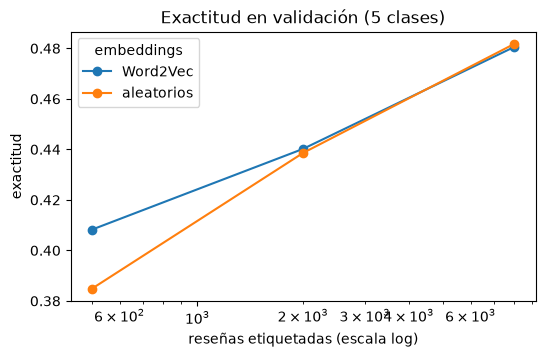

embeddings,Word2Vec,aleatorios
n,,
500,0.4082,0.3848
2000,0.4402,0.4386
8000,0.4806,0.4818


In [9]:
def modelo_promedio_5(inicial=None):
    init = keras.initializers.Constant(inicial) if inicial is not None else "uniform"
    m = keras.Sequential([keras.Input(shape=(LONGITUD,), dtype="int64"),
                          layers.Embedding(len(vocab), 64, mask_zero=True, embeddings_initializer=init),
                          layers.GlobalAveragePooling1D(), layers.Dense(32, activation="relu"),
                          layers.Dense(5, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


filas = []
rng = np.random.default_rng(SEED)
for n in [500, 2000, 8000]:
    idx = rng.choice(len(X_train), size=n, replace=False)
    for nombre, inicial in [("aleatorios", None), ("Word2Vec", matriz)]:
        keras.utils.set_random_seed(SEED)
        m = modelo_promedio_5(inicial)
        m.fit(X_train[idx], y_train[idx], validation_data=(X_val, y_val), epochs=30, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
        filas.append({"n": n, "embeddings": nombre, "exactitud": m.evaluate(X_val, y_val, verbose=0)[1]})

curva = pd.DataFrame(filas).pivot(index="n", columns="embeddings", values="exactitud")
curva.plot(marker="o", logx=True, figsize=(6, 3.5), title="Exactitud en validación (5 clases)")
plt.xlabel("reseñas etiquetadas (escala log)")
plt.ylabel("exactitud")
plt.show()
curva.round(4)

**Interpretación:** con **500** ejemplos etiquetados, los embeddings Word2Vec dan una ventaja de un par de puntos: el modelo aleatorio no tiene forma de saber qué significan miles de palabras que vio una o dos veces, mientras que los vectores preentrenados ya agrupan sinónimos y variantes ortográficas. Con 2 000 y 8 000 ejemplos la ventaja desaparece: el modelo aleatorio aprende por su cuenta las palabras que importan para esta tarea. Con un clasificador tan simple como el promedio, el beneficio del preentrenamiento se concentra en el régimen de muy pocos datos. Los modelos preentrenados del módulo 4, que aportan representaciones **contextuales** y no solo vectores por palabra, extienden mucho más esta ventaja.

---

<a id="ejercicio-5"></a>
<h2 style="color: #007ACC;">Ejercicio 5. Análisis de errores en un problema ordinal</h2>

**Objetivo:** entender qué confusiones comete el mejor modelo y cuánto se deben a la ambigüedad de las propias etiquetas.

1. Elige el mejor modelo de los ejercicios 2–3 según **validación** y evalúalo **una vez** en **prueba** con las métricas del ejercicio 2.
2. Muestra su matriz de confusión normalizada por fila. ¿Dónde se concentran los errores?
3. Calcula el *recall* por clase. ¿Qué clase es la más difícil y por qué crees que ocurre?
4. Muestra 6 reseñas de prueba en las que el error es de 3 o más estrellas. Léelas y clasifica la causa probable: error del modelo, etiqueta inconsistente con el texto, ironía, reseña sobre el envío y no sobre el producto, etc.

Mejor modelo en validación: promedio
Prueba: {'exactitud': 0.5096, 'exactitud ±1': 0.8916, 'MAE': 0.634}


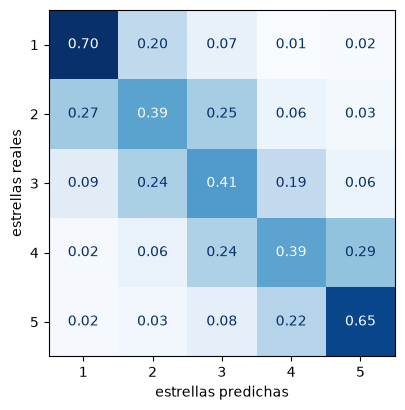

,1,2,3,4,5
recall,0.704,0.393,0.414,0.391,0.646


In [10]:
tabla_val = pd.DataFrame([
    {"modelo": nombre, **metricas(y_val, m.predict(X_val, verbose=0).argmax(axis=1))} for nombre, m in modelos.items()
]).set_index("modelo")
mejor = tabla_val["exactitud"].idxmax()
print(f"Mejor modelo en validación: {mejor}")

pred_test = modelos[mejor].predict(X_test, verbose=0).argmax(axis=1)
print("Prueba:", {k: round(v, 4) for k, v in metricas(y_test, pred_test).items()})

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test + 1, pred_test + 1, normalize="true", values_format=".2f",
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_xlabel("estrellas predichas")
ax.set_ylabel("estrellas reales")
plt.show()

recall = pd.Series({e + 1: (pred_test[y_test == e] == e).mean() for e in range(5)}, name="recall")
recall.round(3).to_frame().T

In [11]:
pd.set_option("display.max_colwidth", 200)
grandes = np.where(np.abs(pred_test - y_test) >= 3)[0]
print(f"Errores de 3 o más estrellas: {len(grandes)} de {len(y_test)} ({len(grandes) / len(y_test):.1%})")
muestra = np.random.default_rng(SEED).choice(grandes, size=min(6, len(grandes)), replace=False)
pd.DataFrame({"reseña": [X_test_txt[i] for i in muestra], "real": y_test[muestra] + 1, "predicha": pred_test[muestra] + 1})

Errores de 3 o más estrellas: 135 de 5000 (2.7%)


,reseña,real,predicha
0,el problema es que amazon solo deje comprar 5 como maximo por persona,5,1
1,Magnífico! es el tercero que compro porque por error... lo tiramos a la basura!!,5,1
2,"lo compré para mi bici pero finalmente se lo ha quedado el xiaomi scooter. Le va que ni pintado. Este modelo nuevo no llevaba timbre, así que este le queda perfecto. Se ajusta al manillas y no bai...",5,1
3,"hace tiempo he comprado la maquinita de fuma,pero no he comprado el liquido,por que en serio no se como funciona,al final me recomentado una amiga.y al final me compre este paquete de liquido,vien...",5,2
4,Lo que se anuncia . Sin nada raro. A mis gatas les encanta y yo feliz para evitar que salga la arena.,2,5
5,"Todo lo que sea dragon ball siempre me gusta, lo que no me gusta es que llegue arrugado y sucio, y más artículos de colección. Es una putada muy grande",1,5


**Interpretación:**

- La matriz de confusión tiene forma de **banda**: casi todos los errores caen en clases **vecinas**. El modelo capta bien la polaridad general; lo difícil es la intensidad.
- Los extremos (1 y 5 estrellas) tienen el *recall* más alto (≈65–70 %), y las tres clases intermedias rondan el 40 %. Las reseñas de 2, 3 y 4 estrellas mezclan aspectos positivos y negativos (*"bonito pero de mala calidad"*), y las fronteras entre ellas son muy subjetivas.
- Los errores grandes (≥ 3 estrellas) son raros. Al leerlos, una parte considerable corresponde a reseñas cuyo texto parece contradecir la calificación (texto positivo con 1 estrella, quejas sobre el envío o el vendedor con calificación alta), a ironía o a reseñas muy cortas sin información. Ningún modelo puede acertar etiquetas inconsistentes con el texto: el techo de exactitud de esta tarea está bastante por debajo del 100 %.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Chollet, F. (2021). *Deep Learning with Python* (2.ª ed.). Manning.
- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Keung, P., Lu, Y., Szarvas, G. & Smith, N. A. (2020). The Multilingual Amazon Reviews Corpus. *EMNLP*.